# FleetReadiness — FD001 exploration

Phase 1 only. This notebook inspects the NASA C-MAPSS turbofan degradation files and calculates training remaining-useful-life labels. It does not train a model.

FleetReadiness is a research prototype. It is not a certified maintenance, flight-safety, or engine-health system. FD001 is simulated data from C-MAPSS, not recordings from an in-service aircraft.

The raw files in `data/raw/` are the original archive contents and are not modified by this notebook.


## 1. Source of the files

The files used here are the original Prognostics Center of Excellence text files, including `readme.txt` and the Saxena et al. paper PDF that ships in the same archive.

| Item | Value |
|---|---|
| Archive | `CMAPSSData.zip` |
| Download used | Zenodo record 15346912, because the NASA legacy zip URL returned no data in this environment |
| DOI | [10.5281/zenodo.15346912](https://doi.org/10.5281/zenodo.15346912) |
| Published MD5 | `79a22f36e80606c69d0e9e4da5bb2b7a` |
| Zenodo license | CC BY 4.0 |
| NASA catalog page | [CMAPSS Jet Engine Simulated Data](https://data.nasa.gov/dataset/cmapss-jet-engine-simulated-data) |
| Paper in the archive | A. Saxena, K. Goebel, D. Simon, and N. Eklund, *Damage Propagation Modeling for Aircraft Engine Run-to-Failure Simulation*, PHM08, 2008 |

The NASA data catalog describes the same layout. This notebook checks the local zip against the published Zenodo MD5 before trusting the extracted files.

Phase 1 uses **FD001 only**. The archive also contains FD002, FD003, and FD004. Those files stay in `data/raw/` and are not analyzed here.


In [1]:
from pathlib import Path
import hashlib

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

def find_root() -> Path:
    start = Path.cwd().resolve()
    for candidate in [start, *start.parents]:
        if (candidate / "data" / "raw" / "train_FD001.txt").exists():
            return candidate
    raise FileNotFoundError("Could not find data/raw/train_FD001.txt")

ROOT = find_root()
RAW = ROOT / "data" / "raw"
FIG = ROOT / "notebooks" / "figures"
FIG.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.grid": True,
    "grid.color": "#d0d5dd",
    "grid.linewidth": 0.6,
    "axes.spines.top": False,
    "axes.spines.right": False,
    "font.size": 11,
    "axes.titlesize": 12,
})

zip_path = RAW / "CMAPSSData.zip"
digest = hashlib.md5(zip_path.read_bytes()).hexdigest()
expected = "79a22f36e80606c69d0e9e4da5bb2b7a"
print(f"root: {ROOT}")
print(f"MD5:  {digest}")
print(f"matches published Zenodo MD5: {digest == expected}")
if digest != expected:
    raise RuntimeError("CMAPSSData.zip does not match the published MD5")


root: /Users/vincekariuki/Desktop/Fleet
MD5:  79a22f36e80606c69d0e9e4da5bb2b7a
matches published Zenodo MD5: True


## 2. What the readme actually says

`data/raw/readme.txt` is the 2008 file from the archive. It is Windows-1252 text (bytes `0x96`, `0x93`, and `0x94`), so it is not valid UTF-8. It is left unchanged.

The readme states that each row has **26 columns**:

1. unit number
2. time, in cycles
3. operational setting 1
4. operational setting 2
5. operational setting 3
6. sensor measurement 1
7. sensor measurement 2
8. ...
9. column 26, which the readme labels "sensor measurement 26"

That last label does not match a file with 26 columns. Columns 1–5 account for the identifier, the cycle, and three settings, which leaves **21 sensor columns** (columns 6 through 26). Saxena et al. (2008) state that 21 of the simulator outputs were provided as the sensor data. There is no 22nd through 26th sensor in the file.

FD001, from the same readme:

- Training trajectories: 100
- Test trajectories: 100
- Conditions: one (sea level)
- Fault mode: one (HPC degradation)

The readme also states that each series is one engine, engines begin with different initial wear, that wear is not treated as a fault, three operational settings affect performance, and the measurements include sensor noise. In the training set the fault grows until failure. In the test set the series ends before failure, and `RUL_FD001.txt` gives the remaining cycles after the last observed test cycle.


## 3. Names used in this notebook

The text files have no header row. Names below are assigned from the readme's column positions. They are not printed in the data file.

Sensor symbols and descriptions come from Table 2 of Saxena et al. (2008), in the order that table lists "parameters available to participants as sensor data." The paper says those 21 outputs are the sensor channels that were recorded. It does not print a header row mapping "column 6" to `T2`. Applying Table 2 in listed order is the documented channel list, and it is labeled that way everywhere below. These names are not invented local abbreviations.

The three operational settings are **not** given physical names. The paper says the simulated flight conditions are combinations of altitude, Mach number, and throttle resolver angle (TRA). It does not say which file column is which. This notebook does not assign those names.

| Column | Name in this project | Basis |
|---|---|---|
| 1 | `unit_number` | Readme: unit number |
| 2 | `time_cycles` | Readme: time, in cycles |
| 3 | `op_setting_1` | Readme: operational setting 1. Physical quantity not stated. |
| 4 | `op_setting_2` | Readme: operational setting 2. Physical quantity not stated. |
| 5 | `op_setting_3` | Readme: operational setting 3. Physical quantity not stated. |
| 6–26 | `sensor_1` … `sensor_21` | Readme positions, 21 channels. Descriptions from Saxena et al. Table 2 in listed order. |


In [2]:
# Saxena et al. 2008, Table 2, "Parameters available to participants as sensor data".
# Index i is the i-th sensor column in the data file (column 5+i).
SENSOR_INFO = [
    (1, "T2", "Total temperature at fan inlet", "°R"),
    (2, "T24", "Total temperature at LPC outlet", "°R"),
    (3, "T30", "Total temperature at HPC outlet", "°R"),
    (4, "T50", "Total temperature at LPT outlet", "°R"),
    (5, "P2", "Pressure at fan inlet", "psia"),
    (6, "P15", "Total pressure in bypass-duct", "psia"),
    (7, "P30", "Total pressure at HPC outlet", "psia"),
    (8, "Nf", "Physical fan speed", "rpm"),
    (9, "Nc", "Physical core speed", "rpm"),
    (10, "epr", "Engine pressure ratio (P50/P2)", "--"),
    (11, "Ps30", "Static pressure at HPC outlet", "psia"),
    (12, "phi", "Ratio of fuel flow to Ps30", "pps/psi"),
    (13, "NRf", "Corrected fan speed", "rpm"),
    (14, "NRc", "Corrected core speed", "rpm"),
    (15, "BPR", "Bypass ratio", "--"),
    (16, "farB", "Burner fuel-air ratio", "--"),
    (17, "htBleed", "Bleed enthalpy", "--"),
    (18, "Nf_dmd", "Demanded fan speed", "rpm"),
    (19, "PCNfR_dmd", "Demanded corrected fan speed", "rpm"),
    (20, "W31", "HPT coolant bleed", "lbm/s"),
    (21, "W32", "LPT coolant bleed", "lbm/s"),
]

ID_COLUMNS = ["unit_number", "time_cycles"]
SETTING_COLUMNS = ["op_setting_1", "op_setting_2", "op_setting_3"]
SENSOR_COLUMNS = [f"sensor_{i}" for i in range(1, 22)]
COLUMNS = ID_COLUMNS + SETTING_COLUMNS + SENSOR_COLUMNS
assert len(COLUMNS) == 26
assert len(SENSOR_INFO) == 21

sensor_lookup = {
    f"sensor_{idx}": {"symbol": symbol, "description": description, "units": units}
    for idx, symbol, description, units in SENSOR_INFO
}

def load_cycles(path: Path) -> pd.DataFrame:
    frame = pd.read_csv(path, sep=r"\s+", header=None, names=COLUMNS, engine="python")
    if frame.shape[1] != 26:
        raise ValueError(f"{path.name} has {frame.shape[1]} columns, expected 26")
    return frame

def load_rul(path: Path) -> pd.Series:
    frame = pd.read_csv(path, sep=r"\s+", header=None, names=["rul"], engine="python")
    return frame["rul"].astype(int)

train = load_cycles(RAW / "train_FD001.txt")
test = load_cycles(RAW / "test_FD001.txt")
rul_test = load_rul(RAW / "RUL_FD001.txt")

print(f"train rows: {len(train):,}   engines: {train['unit_number'].nunique()}")
print(f"test rows:  {len(test):,}   engines: {test['unit_number'].nunique()}")
print(f"RUL file entries: {len(rul_test)}")
train.head(3)


train rows: 20,631   engines: 100
test rows:  13,096   engines: 100
RUL file entries: 100


,unit_number,time_cycles,op_setting_1,op_setting_2,op_setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,...,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0,518.67,641.82,1589.70,1400.60,14.62,...,521.66,2388.02,8138.62,8.4195,0.03,392,2388,100.0,39.06,23.4190
1,1,2,0.0019,-0.0003,100.0,518.67,642.15,1591.82,1403.14,14.62,...,522.28,2388.07,8131.49,8.4318,0.03,392,2388,100.0,39.00,23.4236
2,1,3,-0.0043,0.0003,100.0,518.67,642.35,1587.99,1404.20,14.62,...,522.42,2388.03,8133.23,8.4178,0.03,390,2388,100.0,38.95,23.3442


## 4. Data checks

Checks below are limited to structure and obvious invalid values. They do not decide whether a sensor trace is physically plausible.


In [3]:
def cycle_problems(frame: pd.DataFrame) -> pd.DataFrame:
    problems = []
    for unit, group in frame.groupby("unit_number", sort=True):
        cycles = group["time_cycles"].to_numpy()
        expected = np.arange(1, len(cycles) + 1)
        if not np.array_equal(cycles, expected):
            problems.append({"unit_number": int(unit), "rows": len(cycles), "first": int(cycles[0]), "last": int(cycles[-1])})
    return pd.DataFrame(problems)

def summarize(name: str, frame: pd.DataFrame) -> None:
    print(f"\n{name}")
    print(f"  missing values: {int(frame.isna().sum().sum())}")
    print(f"  duplicate unit-cycle rows: {int(frame.duplicated(['unit_number', 'time_cycles']).sum())}")
    print(f"  non-numeric values: none (read_csv would have produced NaN)")
    units = frame["unit_number"].drop_duplicates().to_numpy()
    print(f"  units are 1..{len(units)} in file order: {np.array_equal(units, np.arange(1, len(units) + 1))}")
    broken = cycle_problems(frame)
    print(f"  engines whose cycles are not 1..N with no gaps: {len(broken)}")

summarize("train_FD001", train)
summarize("test_FD001", test)

if len(rul_test) != test["unit_number"].nunique():
    raise RuntimeError("RUL_FD001.txt length does not match the number of test engines")
if not np.array_equal(test["unit_number"].drop_duplicates().to_numpy(), np.arange(1, len(rul_test) + 1)):
    raise RuntimeError("Test engines are not stored in unit order 1..N, so RUL file alignment is unsafe")

print("\nRUL_FD001.txt is one integer per test engine, in unit-number order.")
print(rul_test.describe().round(2).to_string())



train_FD001
  missing values: 0
  duplicate unit-cycle rows: 0
  non-numeric values: none (read_csv would have produced NaN)
  units are 1..100 in file order: True
  engines whose cycles are not 1..N with no gaps: 0

test_FD001
  missing values: 0
  duplicate unit-cycle rows: 0
  non-numeric values: none (read_csv would have produced NaN)
  units are 1..100 in file order: True
  engines whose cycles are not 1..N with no gaps: 0

RUL_FD001.txt is one integer per test engine, in unit-number order.
count    100.00
mean      75.52
std       41.76
min        7.00
25%       32.75
50%       86.00
75%      112.25
max      145.00


## 5. Engine lifecycles and RUL labels

For a training engine the series runs through the simulated failure cycle. The label at cycle \(t\) is:

`RUL(t) = final cycle of that engine − t`

At the last training cycle the label is 0. This uses the end of the run as a label. It is not a model input. A feature built at cycle \(t\) cannot use this value, the final cycle, or any later row.

For a test engine the file ends before failure. `RUL_FD001.txt` is the remaining cycles **after the last observed cycle**. The label at an earlier test cycle would be that value plus the number of cycles still ahead inside the observed file. Only the final test label is needed to understand the file. Phase 2 will persist labels in the processed dataset.


In [4]:
train_life = train.groupby("unit_number")["time_cycles"].max().rename("failure_cycle")
train_labeled = train.merge(train_life, on="unit_number", how="left")
train_labeled["rul"] = train_labeled["failure_cycle"] - train_labeled["time_cycles"]

if (train_labeled["rul"] < 0).any():
    raise RuntimeError("Negative training RUL")
if not (train_labeled.groupby("unit_number")["rul"].min() == 0).all():
    raise RuntimeError("Every training engine should end at RUL 0")

test_life = test.groupby("unit_number")["time_cycles"].max().rename("observed_cycles")
test_summary = test_life.to_frame()
test_summary["rul_after_last_cycle"] = rul_test.to_numpy()
test_summary["inferred_failure_cycle"] = (
    test_summary["observed_cycles"] + test_summary["rul_after_last_cycle"]
)

life_summary = pd.DataFrame({
    "train_failure_cycle": train_life.describe(),
    "test_observed_cycles": test_life.describe(),
    "test_rul_after_last_cycle": test_summary["rul_after_last_cycle"].describe(),
}).round(2)
print("Lifecycle summary")
print(life_summary.to_string())
print()
print(
    f"shortest training run: unit {int(train_life.idxmin())}, {int(train_life.min())} cycles"
)
print(
    f"longest training run:  unit {int(train_life.idxmax())}, {int(train_life.max())} cycles"
)
median_unit = int((train_life - train_life.median()).abs().idxmin())
print(
    f"nearest-to-median training run: unit {median_unit}, {int(train_life.loc[median_unit])} cycles"
)


Lifecycle summary
       train_failure_cycle  test_observed_cycles  test_rul_after_last_cycle
count               100.00                100.00                     100.00
mean                206.31                130.96                      75.52
std                  46.34                 53.59                      41.76
min                 128.00                 31.00                       7.00
25%                 177.00                 88.75                      32.75
50%                 199.00                133.50                      86.00
75%                 229.25                164.25                     112.25
max                 362.00                303.00                     145.00

shortest training run: unit 39, 128 cycles
longest training run:  unit 69, 362 cycles
nearest-to-median training run: unit 26, 199 cycles


## 6. Which channels actually vary in FD001

FD001 has one operating condition. Channels that never change cannot carry a degradation signal in this subset. They may still matter in FD002 or FD004, where the readme says six conditions are used. Nothing is dropped in this phase.

The correlation figure is a screening plot: Pearson correlation between each sensor and the training RUL label, pooled across engines and cycles. A constant channel has no correlation. A strong correlation means the channel moves with remaining life in this simulation. It is not a cause, a feature importance, or a maintenance threshold.


In [5]:
constant_sensors = [col for col in SENSOR_COLUMNS if train[col].nunique(dropna=False) == 1]
varying_sensors = [col for col in SENSOR_COLUMNS if col not in constant_sensors]

rows = []
for col in SENSOR_COLUMNS:
    info = sensor_lookup[col]
    corr = train_labeled[col].corr(train_labeled["rul"])
    rows.append({
        "column": col,
        "table2_symbol": info["symbol"],
        "table2_description": info["description"],
        "units": info["units"],
        "nunique_train": int(train[col].nunique(dropna=False)),
        "std_train": float(train[col].std(ddof=0)),
        "pearson_r_with_training_rul": None if pd.isna(corr) else round(float(corr), 3),
        "constant_in_fd001_train": col in constant_sensors,
    })
channel_summary = pd.DataFrame(rows)
print("Constant in FD001 training data:")
print(channel_summary.loc[channel_summary["constant_in_fd001_train"], ["column", "table2_symbol", "table2_description"]].to_string(index=False))
print()
print("Operational settings")
print(train[SETTING_COLUMNS].agg(["min", "max", "mean", "std", "nunique"]).T.round(6).to_string())
channel_summary


Constant in FD001 training data:
   column table2_symbol             table2_description
 sensor_1            T2 Total temperature at fan inlet
 sensor_5            P2          Pressure at fan inlet
sensor_10           epr Engine pressure ratio (P50/P2)
sensor_16          farB          Burner fuel-air ratio
sensor_18        Nf_dmd             Demanded fan speed
sensor_19     PCNfR_dmd   Demanded corrected fan speed

Operational settings
                   min       max        mean       std  nunique
op_setting_1   -0.0087    0.0087   -0.000009  0.002187    158.0
op_setting_2   -0.0006    0.0006    0.000002  0.000293     13.0
op_setting_3  100.0000  100.0000  100.000000  0.000000      1.0


,column,table2_symbol,table2_description,units,nunique_train,std_train,pearson_r_with_training_rul,constant_in_fd001_train
0,sensor_1,T2,Total temperature at fan inlet,°R,1,0.000000e+00,NaN,True
1,sensor_2,T24,Total temperature at LPC outlet,°R,310,5.000412e-01,-0.606,False
2,sensor_3,T30,Total temperature at HPC outlet,°R,3012,6.131001e+00,-0.585,False
3,sensor_4,T50,Total temperature at LPT outlet,°R,4051,9.000387e+00,-0.679,False
4,sensor_5,P2,Pressure at fan inlet,psia,1,5.329071e-15,0.000,True
5,sensor_6,P15,Total pressure in bypass-duct,psia,2,1.388951e-03,-0.128,False
6,sensor_7,P30,Total pressure at HPC outlet,psia,513,8.850708e-01,0.657,False
7,sensor_8,Nf,Physical fan speed,rpm,53,7.098376e-02,-0.564,False
8,sensor_9,Nc,Physical core speed,rpm,6403,2.208234e+01,-0.390,False
9,sensor_10,epr,Engine pressure ratio (P50/P2),--,1,0.000000e+00,NaN,True


## 7. Plots

Training length is the cycle at which the simulated run ends. Test length is only how long the series was recorded. Those two histograms are not two samples of the same quantity.

The time-series panels use cycle number on the horizontal axis, which is information available at that cycle. The aligned panel uses cycles-before-the-end-of-the-training-run. That alignment needs the failure cycle, so it is an exploratory view of the label, not a feature that a live predictor can compute for an unfinished engine.


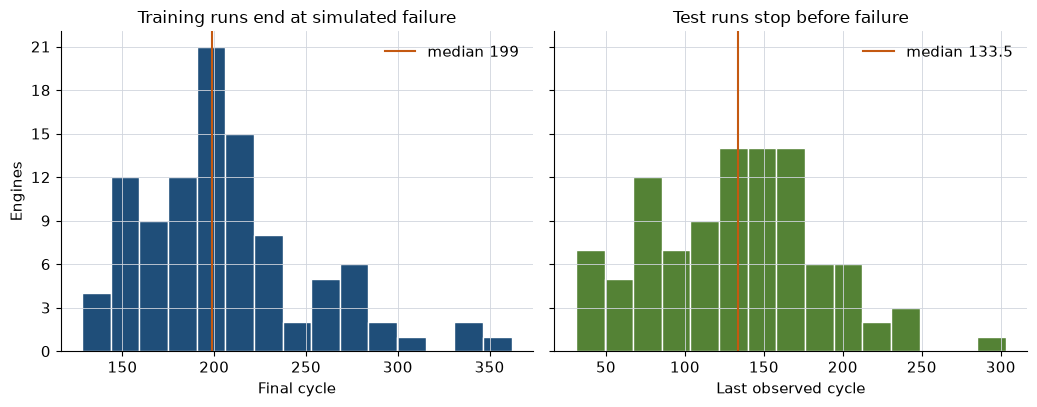

In [6]:
from matplotlib.ticker import MaxNLocator

fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2), sharey=True)
axes[0].hist(train_life.to_numpy(), bins=15, color="#1f4e79", edgecolor="white")
def cycle_label(value: float) -> str:
    number = float(value)
    return str(int(number)) if number.is_integer() else f"{number:.1f}"

axes[0].axvline(train_life.median(), color="#c45911", linewidth=1.5, label=f"median {cycle_label(train_life.median())}")
axes[0].set_title("Training runs end at simulated failure")
axes[0].set_xlabel("Final cycle")
axes[0].set_ylabel("Engines")
axes[0].yaxis.set_major_locator(MaxNLocator(integer=True))
axes[0].legend(frameon=False)

axes[1].hist(test_life.to_numpy(), bins=15, color="#548235", edgecolor="white")
axes[1].axvline(test_life.median(), color="#c45911", linewidth=1.5, label=f"median {cycle_label(test_life.median())}")
axes[1].set_title("Test runs stop before failure")
axes[1].set_xlabel("Last observed cycle")
axes[1].legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "fd001_run_lengths.png", dpi=150, bbox_inches="tight")
plt.show()


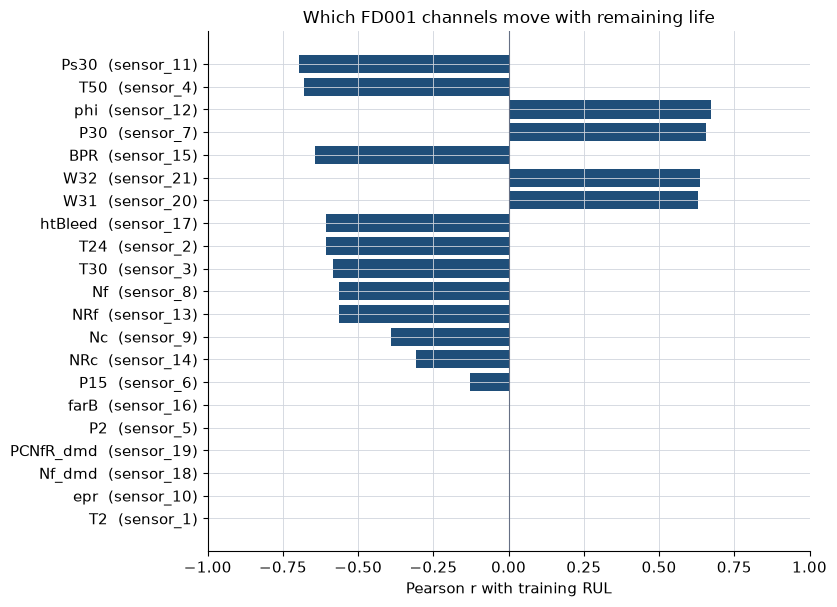

In [7]:
plot_frame = (
    channel_summary
    .assign(abs_r=lambda frame: frame["pearson_r_with_training_rul"].abs())
    .sort_values("abs_r", ascending=True, na_position="first")
)
colors = ["#98a2b3" if flag else "#1f4e79" for flag in plot_frame["constant_in_fd001_train"]]
fig, ax = plt.subplots(figsize=(8.5, 6.2))
ax.barh(
    plot_frame["table2_symbol"] + "  (" + plot_frame["column"] + ")",
    plot_frame["pearson_r_with_training_rul"].fillna(0),
    color=colors,
)
ax.axvline(0, color="#667085", linewidth=0.8)
ax.set_xlabel("Pearson r with training RUL")
ax.set_title("Which FD001 channels move with remaining life")
ax.set_xlim(-1, 1)
fig.tight_layout()
fig.savefig(FIG / "fd001_rul_correlation.png", dpi=150, bbox_inches="tight")
plt.show()


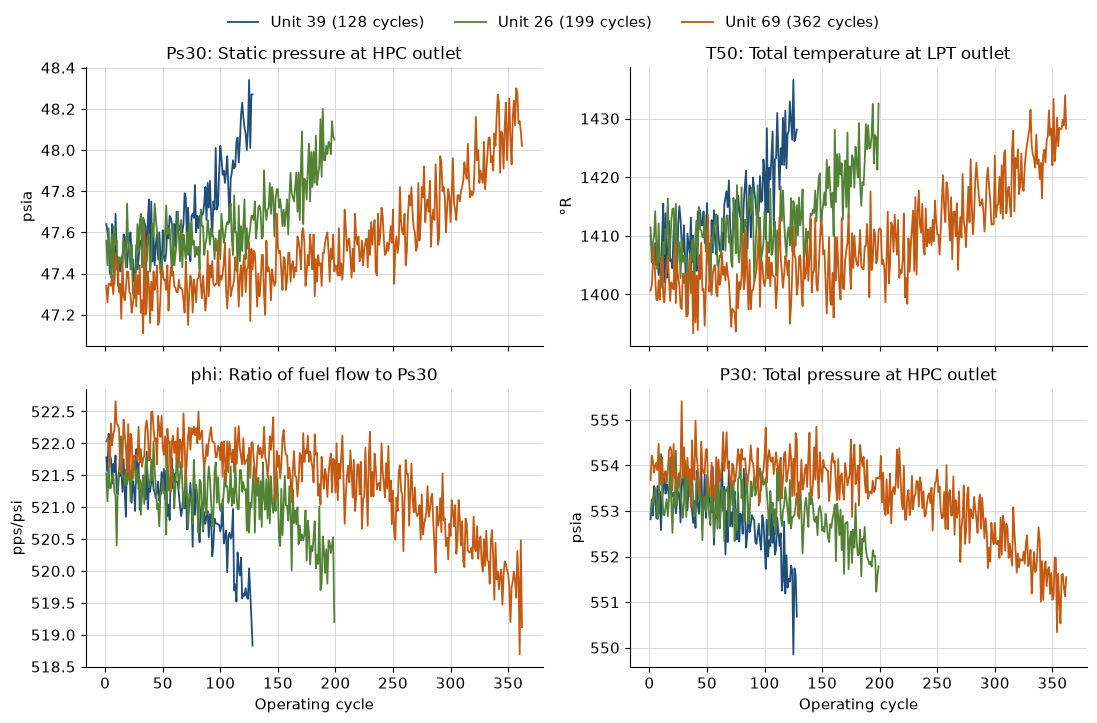

Plotted sensors, strongest |r| first: sensor_11, sensor_4, sensor_12, sensor_7


In [8]:
focus_units = [int(train_life.idxmin()), median_unit, int(train_life.idxmax())]
focus_labels = {
    unit: f"Unit {unit} ({int(train_life.loc[unit])} cycles)" for unit in focus_units
}
focus_colors = {focus_units[0]: "#1f4e79", focus_units[1]: "#548235", focus_units[2]: "#c45911"}
top_sensors = (
    channel_summary
    .assign(abs_r=lambda frame: frame["pearson_r_with_training_rul"].abs())
    .sort_values("abs_r", ascending=False)
    .head(4)["column"]
    .tolist()
)

fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True)
for ax, col in zip(axes.ravel(), top_sensors):
    info = sensor_lookup[col]
    for unit in focus_units:
        subset = train.loc[train["unit_number"] == unit]
        ax.plot(
            subset["time_cycles"],
            subset[col],
            color=focus_colors[unit],
            linewidth=1.3,
            label=focus_labels[unit],
        )
    ax.set_title(f"{info['symbol']}: {info['description']}")
    ax.set_ylabel(info["units"] if info["units"] != "--" else "value")
for ax in axes[1, :]:
    ax.set_xlabel("Operating cycle")
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="upper center", ncol=3, frameon=False, bbox_to_anchor=(0.5, 1.04))
fig.tight_layout()
fig.savefig(FIG / "fd001_sensor_trends.png", dpi=150, bbox_inches="tight")
plt.show()
print("Plotted sensors, strongest |r| first:", ", ".join(top_sensors))


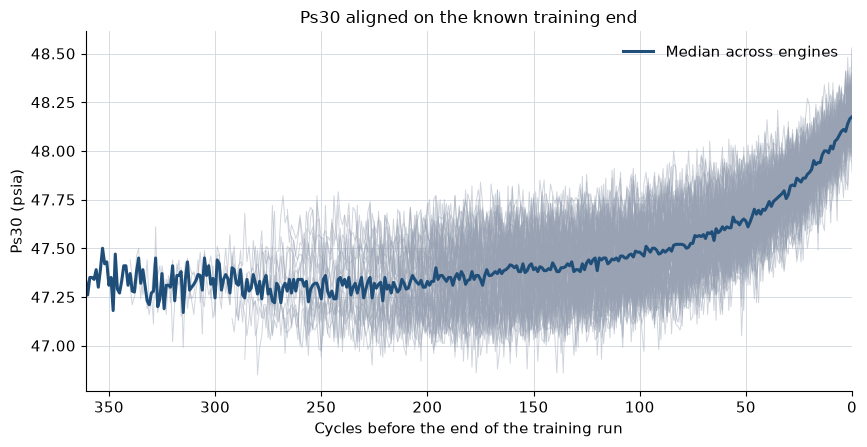

In [9]:
aligned_sensor = top_sensors[0]
info = sensor_lookup[aligned_sensor]
fig, ax = plt.subplots(figsize=(8.8, 4.6))
for unit, subset in train_labeled.groupby("unit_number"):
    ax.plot(
        subset["rul"],
        subset[aligned_sensor],
        color="#98a2b3",
        linewidth=0.7,
        alpha=0.45,
    )
median_path = train_labeled.groupby("rul")[aligned_sensor].median().sort_index()
ax.plot(median_path.index, median_path.to_numpy(), color="#1f4e79", linewidth=2.2, label="Median across engines")
ax.set_xlim(median_path.index.max(), 0)
ax.set_xlabel("Cycles before the end of the training run")
ax.set_ylabel(f"{info['symbol']} ({info['units']})" if info["units"] != "--" else info["symbol"])
ax.set_title(f"{info['symbol']} aligned on the known training end")
ax.legend(frameon=False)
fig.tight_layout()
fig.savefig(FIG / "fd001_aligned_degradation.png", dpi=150, bbox_inches="tight")
plt.show()


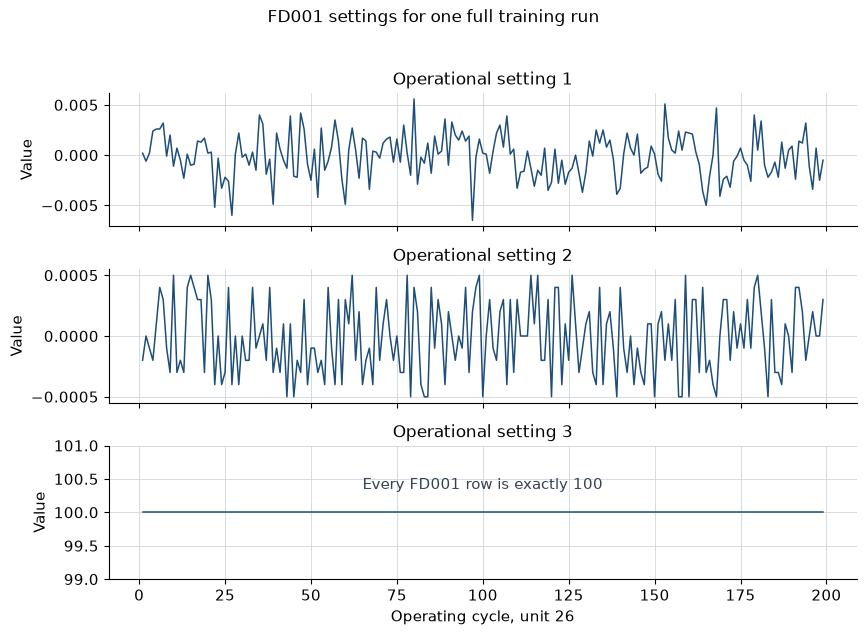

Setting 3 unique values in train and test:
 train [100.0]
 test  [100.0]


In [10]:
example = train.loc[train["unit_number"] == focus_units[1]]
fig, axes = plt.subplots(3, 1, figsize=(8.8, 6.2), sharex=True)
setting_titles = {
    "op_setting_1": "Operational setting 1",
    "op_setting_2": "Operational setting 2",
    "op_setting_3": "Operational setting 3",
}
for ax, col in zip(axes, SETTING_COLUMNS):
    ax.plot(example["time_cycles"], example[col], color="#1f4e79", linewidth=1.1)
    ax.set_ylabel("Value")
    ax.set_title(setting_titles[col])
axes[2].set_ylim(99, 101)
axes[2].text(
    example["time_cycles"].iloc[len(example) // 2],
    100.35,
    "Every FD001 row is exactly 100",
    ha="center",
    color="#344054",
)
axes[-1].set_xlabel(f"Operating cycle, unit {focus_units[1]}")
fig.suptitle("FD001 settings for one full training run", y=1.02, fontsize=12)
fig.tight_layout()
fig.savefig(FIG / "fd001_operational_settings.png", dpi=150, bbox_inches="tight")
plt.show()
print("Setting 3 unique values in train and test:")
print(" train", sorted(train["op_setting_3"].unique().tolist()))
print(" test ", sorted(test["op_setting_3"].unique().tolist()))


## 8. Findings that matter for the next phase

FD001 is a complete, clean table for a first pipeline. Every training and test row has 26 numeric fields, no missing values, and no duplicate unit-cycle keys. Each engine's cycles are `1, 2, ..., N` with no gaps. There are 100 training engines and 100 test engines. Training runs last from 128 to 362 cycles. Test series are shorter because they were cut off before the simulated failure, and the RUL file has the remaining cycles after each cutoff.

Six sensor channels are constant on every FD001 training and the same values repeat in the test file: sensors 1, 5, 10, 16, 18, and 19 in Table 2 order (`T2`, `P2`, `epr`, `farB`, `Nf_dmd`, `PCNfR_dmd`). Sensor 6 (`P15`) takes only two distinct values. Operational setting 3 is exactly 100 on every FD001 row. Settings 1 and 2 jitter in a narrow band around zero and do not trend with cycle. That matches the readme's "one (sea level)" condition. It does not identify which setting is altitude, Mach, or TRA.

The channels with the strongest linear association with training RUL are, in Table 2 order symbols, `Ps30`, `T50`, `phi`, and `P30` (sensors 11, 4, 12, and 7). Several other channels move as well. Early in a run the traces are comparatively flat; more of the movement shows up late, once the series are aligned on the known training end. The readme's fault mode for FD001 is HPC degradation. These plots do not identify which physical part is degrading, and they do not justify a maintenance limit.

The original files were not rewritten. RUL above is a label computed in memory.

### Not done yet

Phase 2 should turn this into reusable code, still on FD001:

- A loader that preserves `data/raw/` and writes processed tables elsewhere.
- Engine-level train and validation splits. Do not split individual cycles at random.
- Rolling means, rolling standard deviations, and cycle-to-cycle differences that use only the current row and earlier rows of the same engine.
- An explicit decision about constant FD001 channels, documented rather than silently dropped.
- Saved training labels using `failure cycle − current cycle` for training engines.
- Tests that a feature at cycle \(t\) does not change when rows after \(t\) are deleted.
